# Acupuncture utilization: patient-level logistic regression

Convert long patient-condition data to one row per patient, fit a ridge logistic
regression with nonlinear age, and inspect validated probabilities and user counts.
This notebook is self-contained: the accompanying Python script is not required.

The model estimates utilization under observed patterns. A current-use flag does
not identify the maximum possible demand or how many nonusers will newly start.

## 1. Dependencies

Use Python 3.10 or later. If needed, uncomment and run the installation line below,
then restart the kernel. All model/data processing occurs locally.

In [1]:
%%time
from __future__ import annotations
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
import pyodbc
import urllib
from sqlalchemy import create_engine
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('error', category=ConvergenceWarning)
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1
CPU times: total: 6.38 s
Wall time: 10.1 s


## import the data

In [2]:
%%time
# establish the connection parameters
odbc_str = ("DRIVER={ODBC Driver 18 for SQL Server};"
            "SERVER=VHACDWA01.vha.med.va.gov,1433;"
            "DATABASE=OPCCCT_CIH;"
            "Trusted_Connection=yes;"
            "Encrypt=yes;"
            "TrustServerCertificate=no;")

# connect
params = urllib.parse.quote_plus(odbc_str)
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

# read in the data
df = pd.read_sql("SELECT * FROM [OPCCCT_CIH].[dflt].[logit_patient_data]", engine)
df = df.loc[df['gender'].notnull()]

CPU times: total: 2min 59s
Wall time: 7min 10s


## 2. Configuration — edit this cell

`USE_COUNTS = True` includes condition-specific diagnosis counts after a
`log(1 + count)` transformation. Set it to `False` to use condition presence only.

Counts must come from comparable baseline windows before the outcome and exclude
acupuncture-generated diagnoses. Frequency can reflect contact with healthcare,
not just severity. The flag must be patient-level and consistent across rows.

Leave target paths as `None` unless scoring a separate comparable population.
When changing configuration, restart the kernel and run all cells.

In [3]:
%%time
USE_COUNTS = False
DUPLICATE_COUNTS = "error" # "max" for repeated cumulative totals; "sum" for disjoint counts.
OUTER_FOLDS = 5
RANDOM_SEED = 42
JOBS = 1                   # Increase only if memory/resources allow.

OUTPUT_BASE = Path.cwd() / "acupuncture_notebook_outputs"
run_name = "patient_analysis"
run_name += "_counts" if USE_COUNTS else "_presence"
OUTPUT_DIR = OUTPUT_BASE / run_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUTPUT_DIR.resolve())

Output folder: C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_notebook_outputs\patient_analysis_presence
CPU times: total: 0 ns
Wall time: 8.39 ms


## 3. Input checks and long-to-wide transformation

Required long-table columns:
`patientICN, age, condition, times_diagnosed, gender, race, current_acupuncture_user`.

Every condition becomes two columns: `dx__<condition>` and `count__<condition>`.
A missing count for a recorded condition remains missing; unrecorded conditions
receive zero. A missing diagnosis record does not establish clinical absence.
Identifiers and condition codes are preserved as strings.

Duplicate patient-condition pairs require an explicit count aggregation rule.
Conflicting patient demographics/outcomes cause an error instead of an arbitrary
choice. Keep granular condition subtypes and severity where available.

In [4]:
%%time
ID = "PatientICN"
OUTCOME = "current_acupuncture_user"
PERSON_FIELDS = ["age", "gender", "race_mod",'rurality', OUTCOME]

def long_to_wide(
    long: pd.DataFrame,
    *,
    duplicate_counts: str = "error",
) -> tuple[pd.DataFrame, list[str]]:
    tables = [long.reindex(columns=[ID] + PERSON_FIELDS)]
    info = pd.concat(tables, ignore_index=True).drop_duplicates()
    info = info.loc[~info.index.duplicated(keep='first')]
    info['count'] = info.groupby(['PatientICN'])['PatientICN'].transform('count')
    info['unknown_count'] = np.where(info['race_mod']=='UNKNOWN', 1,0)
    info['count_unknown'] = info.groupby(['PatientICN'])['unknown_count'].transform('sum')
    info['remove'] = np.where((info['count']>=2) & (info['count_unknown']<info['count']) & (info['race_mod']=='UNKNOWN'), 1, 0)
    info = info.loc[(info['remove']==0)]
    info = info.drop_duplicates(subset=[ID],keep="first")
    group = info.groupby(ID, sort=False)
    conflicts = group[PERSON_FIELDS].nunique(dropna=True).gt(1).sum()
    if conflicts.any():
        details = {k: int(v) for k, v in conflicts.items() if v}
        raise ValueError(
            f"Conflicting patient-level values (counts by field): {details}. "
            "Resolve these at a common index date; do not arbitrarily take first."
        )
    # first() selects the first nonmissing value only after consistency checks.
    people = group[PERSON_FIELDS].first()
    people.index.name = ID
    for col in ["gender", "race_mod"]:
        people[col] = people[col].fillna("__MISSING__").astype(str)
    
    dx = long.loc[long["condition"].notna(), [ID, "condition", "times_diagnosed"]].copy()
    dx['times_diagnosed'] = dx.groupby([ID,'condition'])['times_diagnosed'].transform('sum')
    dx = dx.drop_duplicates()
    
    known_counts = dx["times_diagnosed"].dropna()
    if known_counts.lt(1).any() or not np.equal(known_counts, np.floor(known_counts)).all():
        raise ValueError("A recorded condition needs a positive integer count or missing.")
    keys = [ID, "condition"]
    if dx.duplicated(keys).any():
        if duplicate_counts == "error":
            raise ValueError(
                "Repeated patient-condition pairs. Use --duplicate-counts max "
                "for repeated cumulative totals or sum for disjoint counts."
            )
        if duplicate_counts == "sum" and dx["times_diagnosed"].isna().any():
            raise ValueError("Cannot sum counts with missing components.")
        dx = dx.groupby(keys, as_index=False)["times_diagnosed"].agg(duplicate_counts)

    conditions = sorted(dx["condition"].unique().tolist())
    if conditions:
        presence = (
            dx.assign(present=1)
            .pivot(index=ID, columns="condition", values="present")
            .reindex(index=people.index, columns=conditions)
            .fillna(0)
            .astype("int8")
        )
        counts = (
            dx.pivot(index=ID, columns="condition", values="times_diagnosed")
            .reindex(index=people.index, columns=conditions)
            .where(presence.eq(1), 0.0)
        )
        people = people.join(presence.add_prefix("dx__")).join(counts.add_prefix("count__"))
    return people.reset_index(), conditions

CPU times: total: 0 ns
Wall time: 6.68 μs


## 4. Model helper functions

The model uses a cubic B-spline for age, categorical gender/race, and simultaneous
condition indicators. This age spline allows a middle-age peak; it is not a
restricted cubic spline. Optional counts are transformed, imputed and scaled.

Ridge regularization stabilizes rare/correlated predictors. The penalty is selected
using log loss within training folds. Preprocessing is also learned within those
folds. Patient IDs and the outcome never enter the feature matrix.

In [12]:
def make_pipeline(conditions: list[str], use_counts: bool) -> Pipeline:
    age = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        # Smooth cubic B-spline with linear tails, not a restricted cubic spline.
        ("spline", SplineTransformer(
            n_knots=4, degree=3, knots="uniform",
            include_bias=False, extrapolation="linear",
        )),
        ("scale", StandardScaler(with_mean=False)),
    ])
    parts = [
        ("age", age, ["age"]),
        ("demographics", OneHotEncoder(handle_unknown="ignore"), ["gender", "race_mod",'rurality']),
    ]
    if conditions:
        parts.append(("diagnosis_presence", "passthrough", [f"dx__{c}" for c in conditions]))
        if use_counts:
            counts = Pipeline([
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("impute", SimpleImputer(
                    strategy="median", add_indicator=True, keep_empty_features=True,
                )),
                ("scale", StandardScaler(with_mean=False)),
            ])
            parts.append(("diagnosis_counts", counts, [f"count__{c}" for c in conditions]))
    return Pipeline([
        ("prepare", ColumnTransformer(parts, remainder="drop")),
        # The default L2 penalty is ridge. Do not balance classes when estimating
        # population prevalence without a subsequent sampling/calibration correction.
        ("logit", LogisticRegression(solver="lbfgs", max_iter=3000, class_weight=None)),
    ])

def fit_search(pipeline: Pipeline, X: pd.DataFrame, y: pd.Series, seed: int, jobs: int):
    if X["age"].nunique(dropna=True) < 2:
        raise ValueError("At least two distinct observed ages are needed for the age spline.")
    folds = min(3, int(y.value_counts().min()))
    if folds < 2:
        raise ValueError("Not enough users/nonusers for inner cross-validation.")
    search = GridSearchCV(
        clone(pipeline), {"logit__C": [0.01, 0.1, 1.0, 10.0]},
        scoring="neg_log_loss",
        cv=StratifiedKFold(folds, shuffle=True, random_state=seed),
        n_jobs=jobs, error_score="raise", refit=True,
    )
    search.fit(X, y)
    return search

def probability_metrics(y: pd.Series, p: np.ndarray) -> dict:
    return {
        "patients": int(len(y)),
        "observed_users": int(y.sum()),
        "sum_predicted_probabilities": float(p.sum()),
        "observed_use_rate": float(y.mean()),
        "mean_predicted_probability": float(p.mean()),
        "roc_auc": float(roc_auc_score(y, p)),
        "average_precision": float(average_precision_score(y, p)),
        "brier_score": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
    }

def score_wide(wide: pd.DataFrame, conditions: list[str]) -> pd.DataFrame:
    # Unseen diagnosis columns do not enter a model that never learned them.
    for c in conditions:
        for prefix in ["dx__", "count__"]:
            col = prefix + c
            if col not in wide:
                wide[col] = 0
    return wide

## 5. Check data

In [13]:
%%time
wide, conditions = long_to_wide(df, duplicate_counts=DUPLICATE_COUNTS)
if wide[OUTCOME].isna().any():
    raise ValueError("Every training patient needs a known 0/1 outcome.")
y = wide[OUTCOME].astype(int)
if y.nunique() != 2 or y.value_counts().min() < 6:
    raise ValueError("Need both users and noanusers, at least six of each for nested CV.")
if OUTER_FOLDS < 2:
    raise ValueError("OUTER_FOLDS must be at least 2.")
# Six is an execution minimum, not assurance of adequate statistical sample size.
feature_columns = ["age", "gender", "race_mod",'rurality'] + [f"dx__{c}" for c in conditions]
if USE_COUNTS:
    feature_columns += [f"count__{c}" for c in conditions]
X = wide[feature_columns]
assert ID not in X.columns and OUTCOME not in X.columns
print(f"Long rows: {len(df):,}; patients: {len(wide):,}; conditions: {len(conditions)}")
print(f"Observed users: {int(y.sum()):,}; nonusers: {int(y.eq(0).sum()):,}")
display(wide.drop(columns=ID).head())

Long rows: 17,452,170; patients: 5,231,037; conditions: 98
Observed users: 206,968; nonusers: 5,024,069


,age,gender,race_mod,rurality,current_acupuncture_user,dx__Abdominal pain,dx__Acute pancreatitis,dx__Adjustment and other stress-related disorders,dx__Alcohol use disorder,dx__Allergic rhinitis,...,count__Stress urinary incontinence,count__Stroke,count__Temporomandibular joint dysfunction,count__Tension Headache,count__Thoracic disc degeneration,count__Tinnitus,count__Tobacco use disorder,count__Tremor,count__Unspecified mood disorder,count__Urinary tract infection
0,76.0,Male,WHITE,4.0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,60.0,Male,HISPANIC OR LATINO,2.0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,62.0,Male,WHITE,4.0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,55.0,Male,WHITE,1.0,0,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,68.0,Male,WHITE,1.0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,6.0,0.0,0.0


CPU times: total: 4min 41s
Wall time: 4min 42s


## 6. Fit and validate

Each patient's validation probability is generated by a model that did not train
on that patient's outcome. Inner cross-validation selects the ridge penalty.
Random folds do not replace later-period or facility-level validation.

Your 0.5% acupuncture-claim condition filter is outcome-derived. These results
validate the model conditional on that supplied list; they do not independently
validate condition selection. Freeze the list from an independent earlier period
or repeat selection within training folds using the original unfiltered data.

In [14]:
%%time
pipeline = make_pipeline(conditions, USE_COUNTS)
outer_folds = min(OUTER_FOLDS, int(y.value_counts().min()))
outer = StratifiedKFold(outer_folds, shuffle=True, random_state=RANDOM_SEED)
oof = np.full(len(wide), np.nan)
fold_number = np.zeros(len(wide), dtype=int)
selected_penalties = []
for fold, (train, test) in enumerate(outer.split(X, y), start=1):
    search = fit_search(pipeline, X.iloc[train], y.iloc[train], RANDOM_SEED + fold, JOBS)
    oof[test] = search.predict_proba(X.iloc[test])[:, 1]
    fold_number[test] = fold
    selected_penalties.append(float(search.best_params_["logit__C"]))
    print(f"Validation fold {fold}/{outer_folds} complete.", flush=True)
assert np.isfinite(oof).all()
final = fit_search(pipeline, X, y, RANDOM_SEED, JOBS)
model = final.best_estimator_
metrics = probability_metrics(y, oof)
print("Final ridge C:", final.best_params_["logit__C"])

Validation fold 1/5 complete.
Validation fold 2/5 complete.
Validation fold 3/5 complete.
Validation fold 4/5 complete.
Validation fold 5/5 complete.
Final ridge C: 0.1
CPU times: total: 3h 27min 46s
Wall time: 36min 13s


## 7. Review performance and calibration

ROC AUC and average precision describe discrimination. Brier score and log loss
assess probability prediction; calibration compares predicted and observed rates.
Check the calibration curve and the overall observed-versus-predicted rate before
using probability sums for planning. Lower Brier score alone does not prove good
calibration. Assess demographic and clinical subgroups and independent data too.

,value
patients,5.231037e+06
observed_users,2.069680e+05
sum_predicted_probabilities,2.069629e+05
observed_use_rate,3.956539e-02
mean_predicted_probability,3.956440e-02
roc_auc,8.217598e-01
average_precision,1.797438e-01
brier_score,3.518722e-02
log_loss,1.393933e-01


,mean_predicted_probability,observed_fraction_users
0,0.007655,0.003204
1,0.010013,0.004710
2,0.011771,0.006758
3,0.013743,0.009052
4,0.016220,0.012344
5,0.019793,0.018453
6,0.026316,0.030679
7,0.040334,0.052003
8,0.066994,0.083240
9,0.182806,0.175212


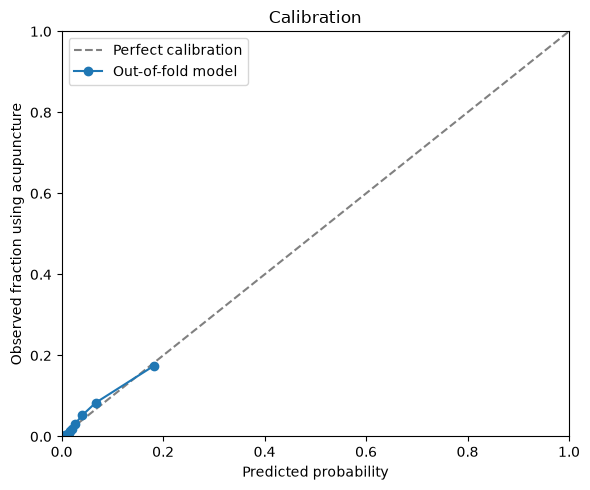

CPU times: total: 734 ms
Wall time: 749 ms


In [15]:
%%time
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))
measured, predicted = calibration_curve(y, oof, n_bins=10, strategy="quantile")
calibration = pd.DataFrame({
    "mean_predicted_probability": predicted,
    "observed_fraction_users": measured,
})
display(calibration)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(predicted, measured, "o-", label="Out-of-fold model")
ax.set(xlabel="Predicted probability", ylabel="Observed fraction using acupuncture",
       xlim=(0, 1), ylim=(0, 1), title="Calibration")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "calibration.png", dpi=150)
plt.show()

## 8. Interpret patient probabilities and user counts

Sum probabilities rather than counting probabilities above 0.5. In the same cohort,
this sum checks whether the model reproduces observed utilization; it will often be
close to the observed user count. It does not reveal a maximum demand ceiling.

The probability sum among known current nonusers is a propensity summary, **not a
forecast of new users**. To forecast initiation, train on baseline nonusers with a
later new-use outcome and appropriate follow-up. No uncertainty interval or
improved-access intervention is estimated here.

In [16]:
predictions = wide[[ID, OUTCOME]].copy()
predictions["validation_fold"] = fold_number
predictions["probability_oof"] = oof
count_table = pd.DataFrame([
    {"quantity": "Observed current users", "value": int(y.sum())},
    {"quantity": "Sum of validated probabilities in this cohort", "value": float(oof.sum())},
    {"quantity": "Current nonusers", "value": int(y.eq(0).sum())},
    {"quantity": "Nonuser propensity sum — NOT a new-user forecast", "value": float(oof[y.eq(0)].sum())},
])
display(count_table)
display(predictions.drop(columns=ID).head())

,quantity,value
0,Observed current users,2.069680e+05
1,Sum of validated probabilities in this cohort,2.069629e+05
2,Current nonusers,5.024069e+06
3,Nonuser propensity sum — NOT a new-user forecast,1.815931e+05


,current_acupuncture_user,validation_fold,probability_oof
0,0,5,0.016691
1,0,2,0.024001
2,0,1,0.035496
3,0,3,0.109338
4,0,1,0.109253


## 9. Condition summaries and fitted coefficients

These coefficients are regularized conditional associations, not causal effects or
a general importance ranking. Spline coefficients jointly describe age; count
coefficients refer to transformed/scaled values. No conventional p-values or
confidence intervals are supplied. Zero users means zero observed utilization,
not zero clinical benefit. Patients can appear in multiple condition groups;
summing condition-group counts double-counts them.

In [17]:
condition_summary = pd.DataFrame([
    {"condition": c,
     "patients_with_condition": int(wide[f"dx__{c}"].sum()),
     "users_with_condition": int(y[wide[f"dx__{c}"].eq(1)].sum())}
    for c in conditions
], columns=["condition", "patients_with_condition", "users_with_condition"])
coefficients = pd.DataFrame({
    "feature": model.named_steps["prepare"].get_feature_names_out(),
    "ridge_log_odds_coefficient": model.named_steps["logit"].coef_[0],
})
display(condition_summary)
display(coefficients.head(25))

,condition,patients_with_condition,users_with_condition
0,Abdominal pain,141809,9666
1,Acute pancreatitis,8332,497
2,Adjustment and other stress-related disorders,316063,22359
3,Alcohol use disorder,146008,9379
4,Allergic rhinitis,194821,14166
...,...,...,...
93,Tinnitus,135340,9456
94,Tobacco use disorder,282779,15117
95,Tremor,53528,3306
96,Unspecified mood disorder,62607,4238


,feature,ridge_log_odds_coefficient
0,age__age_sp_0,-0.020458
1,age__age_sp_1,-0.508050
2,age__age_sp_2,-0.563550
3,age__age_sp_3,-0.756003
4,age__age_sp_4,-0.343453
5,demographics__gender_Female,0.050868
6,demographics__gender_Male,-0.383765
7,demographics__race_mod_AMERICAN INDIAN OR ALAS...,-0.083443
8,demographics__race_mod_ASIAN,0.375715
9,demographics__race_mod_BLACK OR AFRICAN AMERICAN,-0.319794


## 10. Optional: score a separate comparable population

Set target paths in the configuration cell. The target long CSV has the same
predictor columns; its outcome is optional. Counts/coding/observation windows
should match training. New conditions have no learned effect and are reported.

The target probability sum estimates expected users **under training-period
patterns**, assuming adequate calibration, representative sampling, and comparable
access. It is not a maximum or a causal access-expansion estimate. Scoring overlapping
patients is not independent validation.

## 11. Save outputs

Exports include the wide dataset, patient probabilities, calibration, condition
counts, fitted coefficients, model and summary. These files contain identifiers
where needed for joining back to your source. Outputs stay in `OUTPUT_DIR`.

In [18]:
summary = {
    "data_mode": "input_data",
    "interpretation": "Current-utilization propensity; not a maximum or initiation forecast.",
    "validation": "Nested stratified cross-validation; conditional on the supplied condition list.",
    "use_counts": USE_COUNTS, "conditions": len(conditions),
    "out_of_fold_metrics": metrics,
    "current_nonusers": int(y.eq(0).sum()),
    "nonuser_propensity_sum_NOT_new_user_forecast": float(oof[y.eq(0)].sum()),
    "outer_fold_C": selected_penalties,
    "final_C": float(final.best_params_["logit__C"]),
    "limitations": [
        "Condition selection from the same outcomes is not independently validated.",
        "Counts/conditions must precede the outcome and exclude acupuncture-generated records.",
        "Probability sums require representative sampling, comparable access and calibration.",
        "No maximum, initiation forecast, uncertainty interval, or causal expansion scenario is estimated.",
        "Clinical validity, decision impact, patient benefit and resource optimization: Data Insufficient.",
    ],
}

#wide.to_csv(OUTPUT_DIR / "patients_wide.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "patient_probabilities.csv", index=False)
calibration.to_csv(OUTPUT_DIR / "calibration.csv", index=False)
condition_summary.to_csv(OUTPUT_DIR / "condition_counts.csv", index=False)
coefficients.to_csv(OUTPUT_DIR / "model_coefficients.csv", index=False)
joblib.dump({
    "model": model, "conditions": conditions, "feature_columns": feature_columns,
    "use_counts": USE_COUNTS, "sklearn_version": sklearn.__version__,
}, OUTPUT_DIR / "model.joblib")
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved results to", OUTPUT_DIR.resolve())

Saved results to C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_notebook_outputs\patient_analysis_presence


## Data that would improve the analysis

| Additional data | Necessity (1–5) | Likely source and accessibility |
|---|---:|---|
| Baseline/outcome dates, observation length and full population denominator | 5 | Health-system EHR/claims; nonpublic |
| Whether counts include acupuncture encounters | 5 | Claims service/date linkage; system/payer, nonpublic |
| Independent condition-selection period and original unfiltered conditions | 5 for validating the filter | Original claims/EHR extract; nonpublic |
| Facility, referral/access, wait time and travel distance | 4 for utilization; 5 for expansion | Operational/EHR records; primarily nonpublic |
| Eligibility, contraindications, willingness and service capacity | 5 for achievable demand | Clinical review, surveys and scheduling records; nonpublic |
| Condition severity/duration, comorbidity detail and social needs | 4 | EHR/clinical instruments; nonpublic |

Clinical validity, decision impact, patient-centered benefits and resource
optimization are **Data Insufficient** in this utilization-only model.

To compare presence-only and counts models, change `USE_COUNTS`, restart and rerun.
Selecting a preferred version from those validation results requires independent
confirmation or selection within the inner validation process.

References: [logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[splines](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html),
[calibration](https://scikit-learn.org/stable/modules/calibration.html),
[pandas pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html),
[prediction-model development](https://www.bmj.com/content/386/bmj-2023-078276).